In [1]:
from data_process import *
from mcar.simulate import *
from graphOUedge import GraphOUEdge

def pred_robust(seed: int, p: float, gamma: float, num_node: int, scale: float, T: int, forecast_step: int):
    dir = 'p_' + str(p) + '_gamma_' + str(gamma)
    TICKERS = [str(i) for i in range (num_node)]
    G = nx.erdos_renyi_graph(num_node, p, seed=seed)
    G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))
    A = nx.to_numpy_array(G)

    adj_sim = adj_to_line_graph(A, TICKERS)
    adj_L_sim = adjacency_matrices(adj_sim[0], 1)
    W_C_sim = edge_weight(adj_L_sim)
    X_sim = GraphOUEdge([1], len(adj_sim[1]), 1, adj_L_sim, W_C_sim, gamma, dir, scale=scale, T=T)
    X_sim.alpha_set(np.array([[5]+[1 for _ in range(len(adj_sim[1]) - 1)]]))
    X_sim.beta_set([[2]])
    X_sim.Q_matrix()
    data_sim = X_sim.simulate('CP', 1000, seed=1000, rate=1)

    edges = list(G.edges())
    G_without_first = G.copy()
    first_edge = edges[0]
    G_without_first.remove_edge(*first_edge)
    A_without_first = nx.to_numpy_array(G_without_first, nodelist=TICKERS)

    G_without_last = G.copy()
    last_edge = edges[-1]
    G_without_last.remove_edge(*last_edge)
    A_without_last = nx.to_numpy_array(G_without_last, nodelist=TICKERS)

    model_pred(data=data_sim, test_size=400, adj_sim=adj_sim, forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='correct', scenario=dir)
    model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_first, TICKERS), forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='missing_5', scenario=dir)
    model_pred(data=data_sim, test_size=400, adj_sim=adj_to_line_graph(A_without_last, TICKERS), forecast_step=forecast_step, P_Q_ratio=T**4, gamma=gamma, label='missing_1', scenario=dir)

    boxplot_(data_sim, dir)

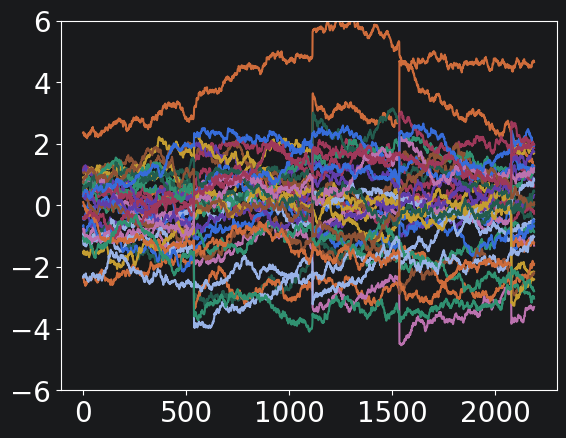

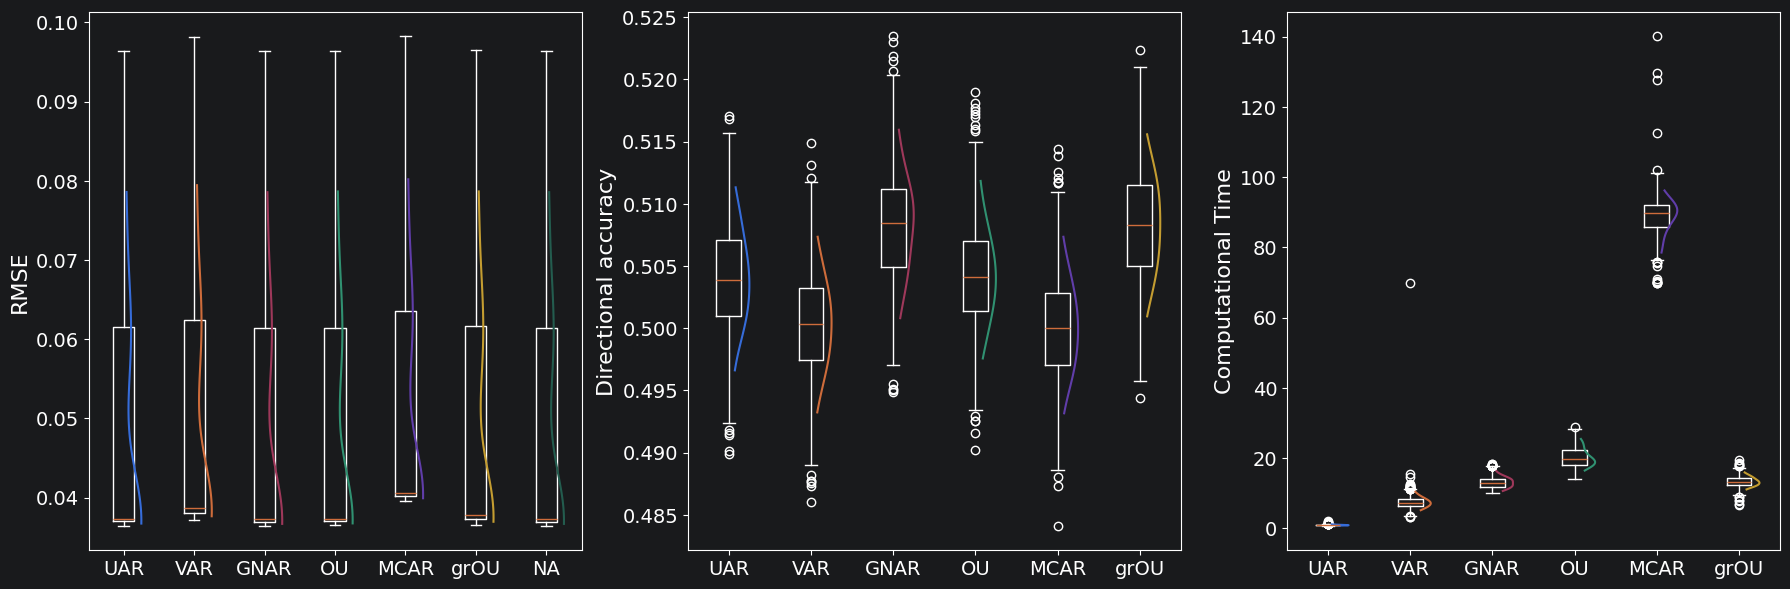

correct
                                UAR       VAR       GNAR         OU  \
RMSE_mean                  0.048903  0.050031   0.048868   0.048947   
RMSE_std                   0.015946  0.015883   0.015948   0.015939   
Directional_accuracy_mean  0.504013  0.500323   0.508226   0.504256   
Directional_accuracy_std   0.004491  0.004332   0.004614   0.004377   
Computational_time_mean    0.907366  7.438891  13.120943  20.269077   
Computational_time_std     0.122072  2.550790   1.673450   2.842135   

                                MCAR       grOU        NA  
RMSE_mean                   0.051639   0.049253  0.048868  
RMSE_std                    0.015337   0.015871  0.015948  
Directional_accuracy_mean   0.500103   0.508307       NaN  
Directional_accuracy_std    0.004289   0.004586       NaN  
Computational_time_mean    88.805218  13.322221       NaN  
Computational_time_std      5.863812   1.517672       NaN  


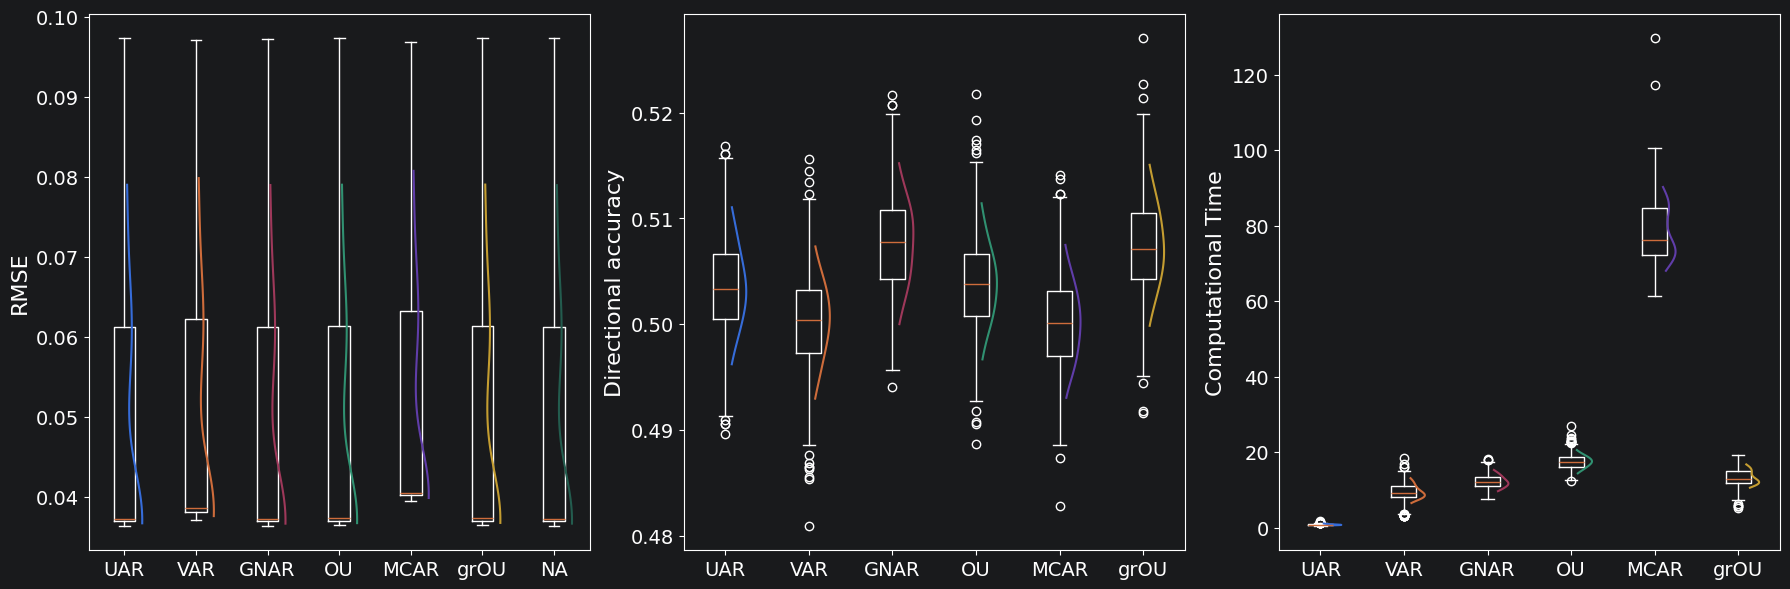

missing_5
                                UAR       VAR       GNAR         OU  \
RMSE_mean                  0.048884  0.049974   0.048849   0.048929   
RMSE_std                   0.015925  0.015858   0.015927   0.015919   
Directional_accuracy_mean  0.503541  0.500273   0.507695   0.503875   
Directional_accuracy_std   0.004541  0.004481   0.004594   0.004405   
Computational_time_mean    0.880865  9.583393  12.326264  17.536491   
Computational_time_std     0.154871  2.147637   1.790754   1.918118   

                                MCAR       grOU        NA  
RMSE_mean                   0.051626   0.048951  0.048847  
RMSE_std                    0.015320   0.015911  0.015927  
Directional_accuracy_mean   0.500116   0.507365       NaN  
Directional_accuracy_std    0.004370   0.004685       NaN  
Computational_time_mean    78.220544  13.404730       NaN  
Computational_time_std      7.732422   2.132230       NaN  


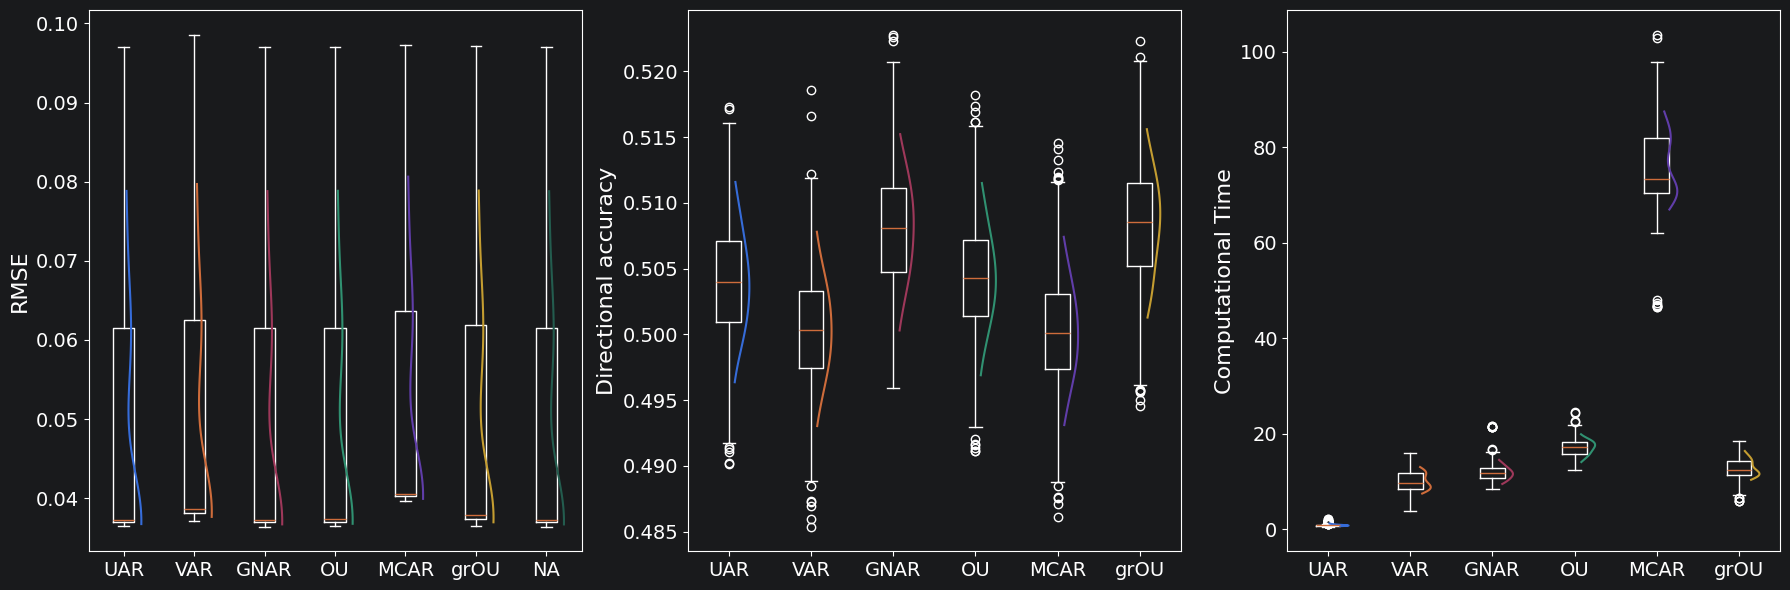

missing_1
                                UAR        VAR       GNAR         OU  \
RMSE_mean                  0.048932   0.050027   0.048899   0.048976   
RMSE_std                   0.015977   0.015919   0.015979   0.015969   
Directional_accuracy_mean  0.503990   0.500347   0.507948   0.504332   
Directional_accuracy_std   0.004574   0.004485   0.004616   0.004424   
Computational_time_mean    0.881084  10.090370  11.910723  17.103190   
Computational_time_std     0.195617   1.969953   1.721251   1.767920   

                                MCAR       grOU        NA  
RMSE_mean                   0.051674   0.049299  0.048897  
RMSE_std                    0.015373   0.015898  0.015980  
Directional_accuracy_mean   0.500154   0.508409       NaN  
Directional_accuracy_std    0.004371   0.004589       NaN  
Computational_time_mean    75.900546  12.900297       NaN  
Computational_time_std      7.381481   2.002915       NaN  


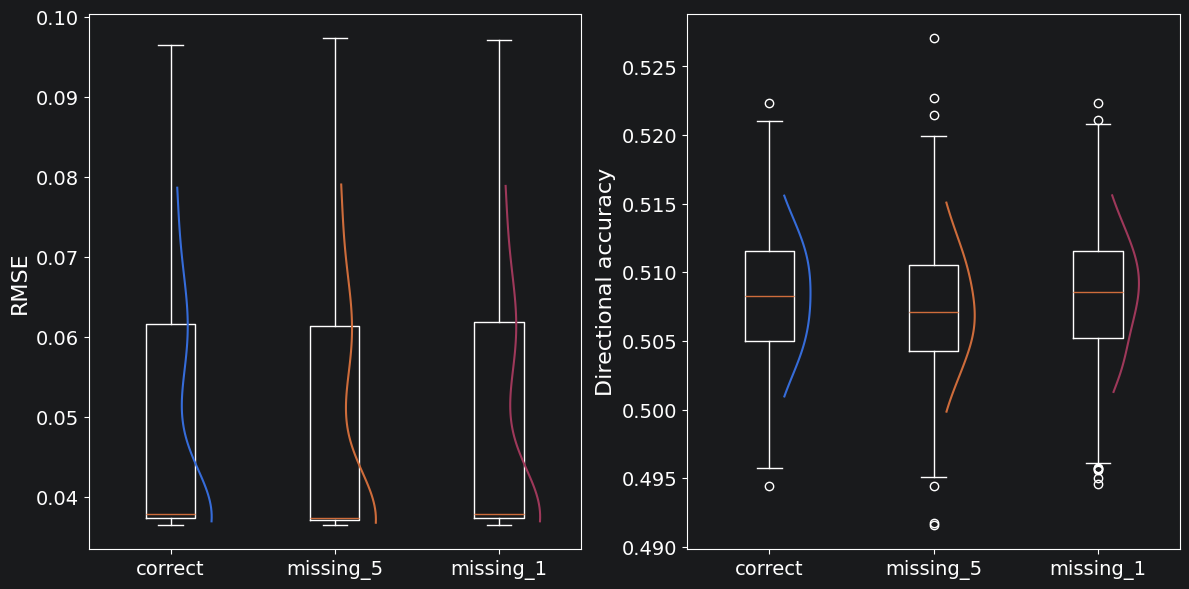

In [4]:
pred_robust(123, 0.15, 1.25, 20, 1, 3, 1)

In [ ]:
#section 4.1 larger graph 20 vertex 34 edges gamma = 1.01, T = 2,4,8, 3 regimes, 2 lags, get parameter estimation error averaged
#section 4.2-4.3 larger graph 20 vertex 34 edges gamma = 1.01, T = 3, 1 regimes, 1 lag, sigma = 1, 10
#section 4.2-4.3 10-edge graph with different gamma and grid only grOU model, jump detection, true/false postiive rate

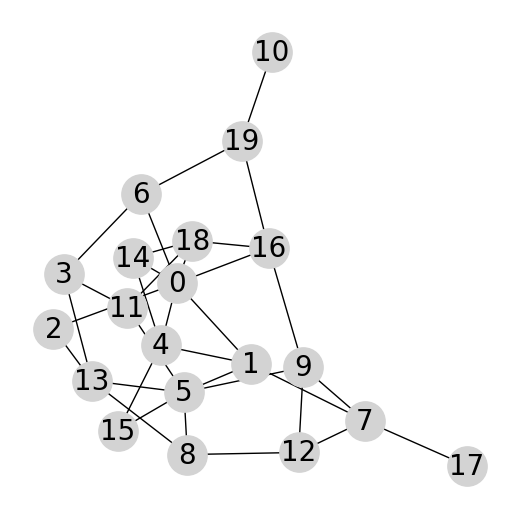

1


In [ ]:
num_node = 20
p = 0.15
seed = 123
gamma = 1.01
scale = 1

TICKERS = [str(i) for i in range (num_node)]
G = nx.erdos_renyi_graph(num_node, p, seed=seed)
G = nx.relabel_nodes(G, dict(enumerate(TICKERS)))
pos = nx.spring_layout(G, seed=1)

plt.figure(figsize=(5, 5))
nx.draw(G, pos, with_labels=True, node_size=800, node_color='lightgrey', font_size=20)
plt.show()

A = nx.to_numpy_array(G)
adj_sim = adj_to_line_graph(A, TICKERS)
adj_L_sim = adjacency_matrices(adj_sim[0], 1)
W_C_sim = edge_weight(adj_L_sim)
X_sim = GraphOUEdge([1,1], len(adj_sim[1]), 1, adj_L_sim, W_C_sim, gamma, '')
X_sim.alpha_set(np.array([[2 for _ in range(len(adj_sim[1]))], [1 for _ in range(len(adj_sim[1]))]]))
X_sim.beta_set([[1],[0.5]])
X_sim.Q_matrix()


for regime in ['BM', 'CP', 'Gamma']:
    estimate = []
    for j in range(200):
        print(str(j + 1))
        sim = X_sim.simulate(regime, 5, seed=134 + 100 * j, rate=1)
        P = np.linspace(0, 8, 8 ** 7 + 1)
        args = [(P, [1,1], len(adj_sim[1]), 1, sim[i], adj_L_sim, W_C_sim, gamma) for i in range(5)]
        with Pool(os.cpu_count()) as pool:
            results = pool.map(process_one_sim, args)
        estimate.extend(results)

    with open('./data/LOBSTERdata/output/sim/large_estimate_' + regime + '.npy', 'wb') as f:
        np.save(f, estimate)

LinAlgError: The data appears to lie in a lower-dimensional subspace of the space in which it is expressed. This has resulted in a singular data covariance matrix, which cannot be treated using the algorithms implemented in `gaussian_kde`. Consider performing principal component analysis / dimensionality reduction and using `gaussian_kde` with the transformed data.

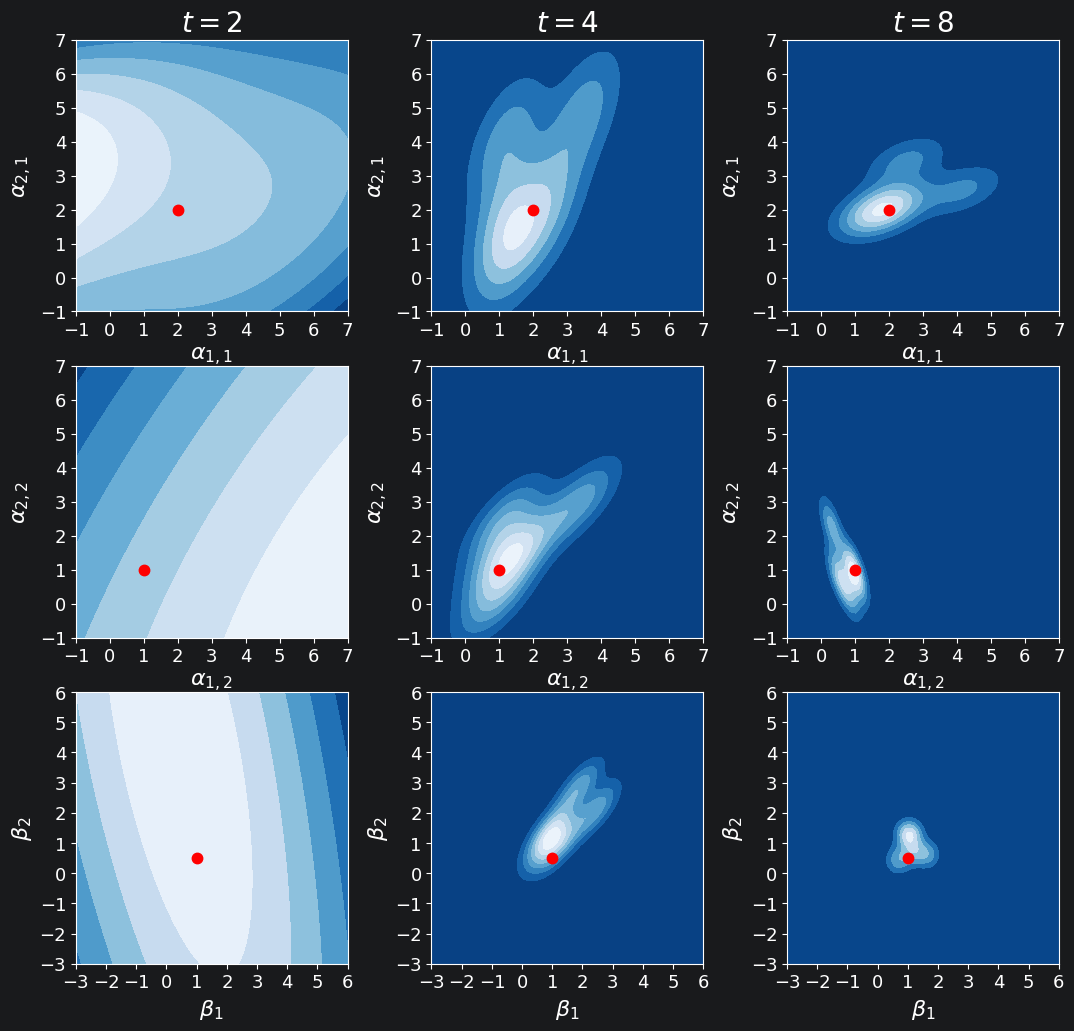

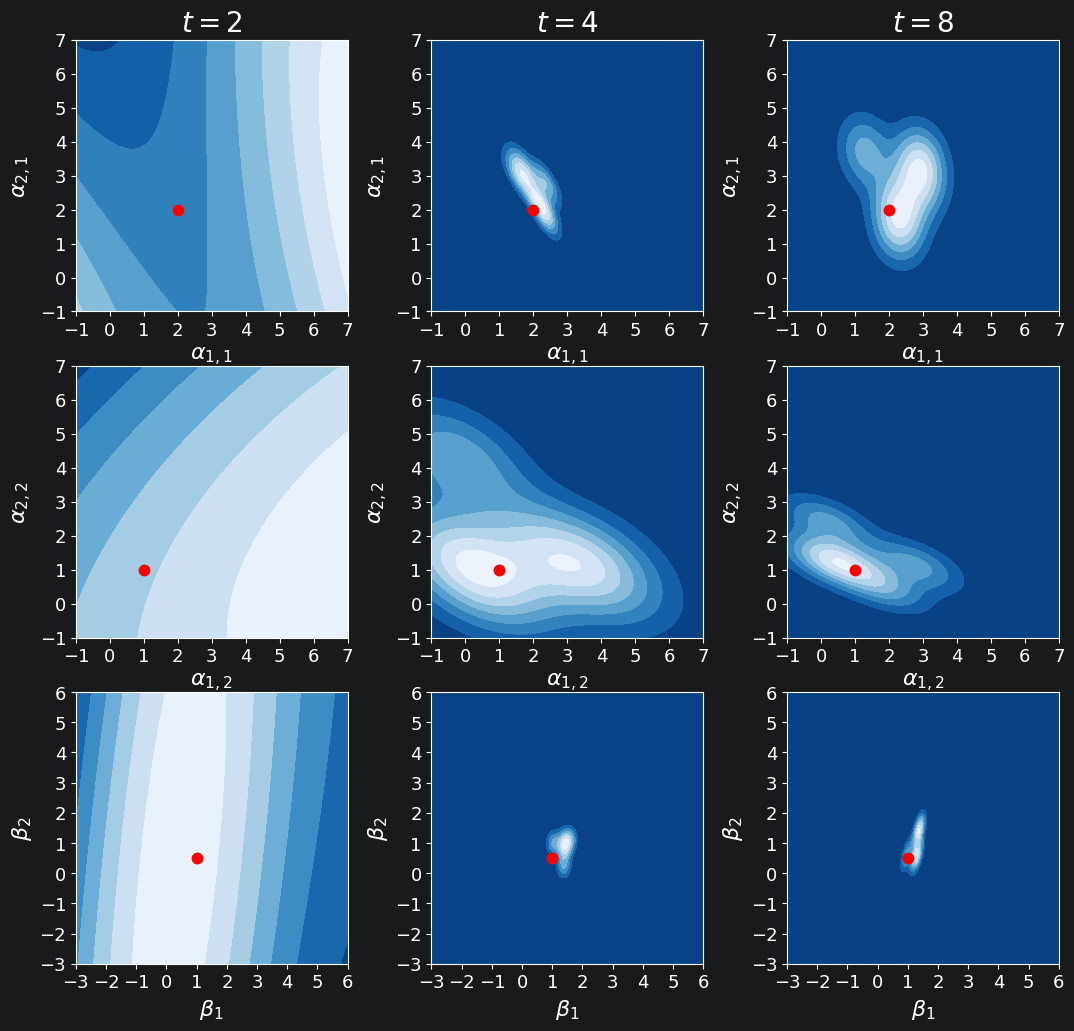

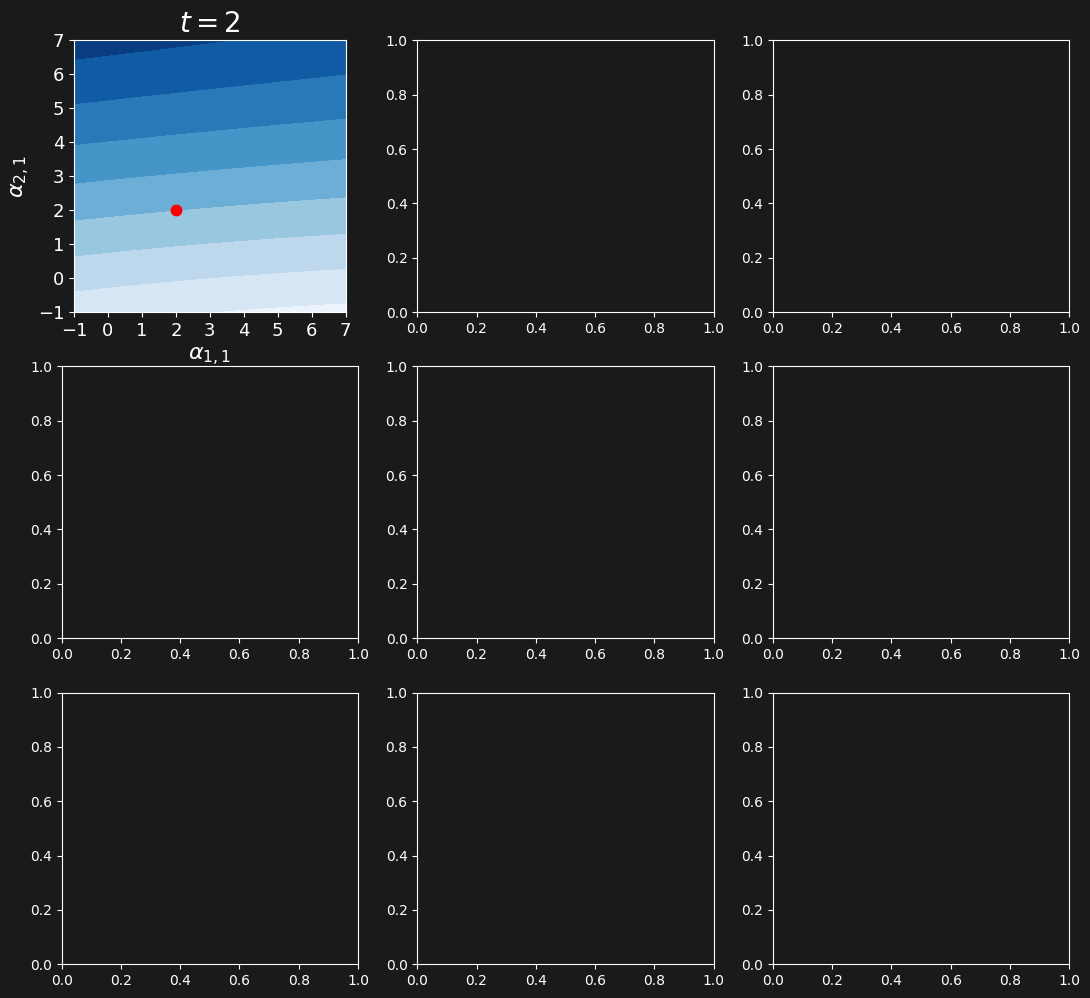

In [3]:
for regime in ['BM', 'CP', 'Gamma']:
    with open('./data/LOBSTERdata/output/sim/large_estimate_' + regime + '.npy', 'rb') as f:
        estimate = np.load(f)

    fig, axes = plt.subplots(3, 3, figsize=(13, 12), squeeze=False)
    for log2t in range(1, 4):
        for n in range(2):
            for m in range(1):
                ax = axes[n, log2t - 1]
                x = estimate[:, log2t - 1, n * 35 + m]
                y = estimate[:, log2t - 1, n * 35 + m + 1]
                mask = (abs(x) < 100) & (abs(y) < 100)
                x_clean = x[mask]
                y_clean = y[mask]

                k = scipy.stats.gaussian_kde(np.vstack([x_clean, y_clean]))
                xi, yi = np.mgrid[-1:7:100 * 1j, -1:7:100 * 1j]
                zi = k(np.vstack([xi.flatten(), yi.flatten()]))

                ax.contourf(xi, yi, zi.reshape(xi.shape), cmap='Blues_r')

                ax.set_xticks([-1, 0, 1, 2, 3, 4, 5, 6, 7])
                ax.set_yticks([-1, 0, 1, 2, 3, 4, 5, 6, 7])
                ax.tick_params(axis='both', labelsize=13)
                ax.set_xlabel(r'$\alpha_{%i,%i}$' % (2 * m + 1, n + 1), fontsize=16)
                ax.set_ylabel(r'$\alpha_{%i,%i}$' % (2 * m + 2, n + 1), fontsize=16)
                ax.plot(X_sim.Q_get()[n][2 * m][2 * m], X_sim.Q_get()[n][2 * m + 1][2 * m + 1], color='red', marker='.', markersize=15)
                ax.set_box_aspect(1)

                if n == 0 and m == 0:
                    ax.set_title(r'$t = %i$' % 2 ** log2t, fontsize=20)

        ax = axes[2, log2t - 1]
        x = estimate[:, log2t - 1, 34]
        y = estimate[:, log2t - 1, 69]
        mask = (abs(x) < 100) & (abs(y) < 100)
        x_clean = x[mask]
        y_clean = y[mask]

        k = scipy.stats.gaussian_kde(np.vstack([x_clean, y_clean]))
        xi, yi = np.mgrid[-3:6:100 * 1j, -3:6:100 * 1j]
        zi = k(np.vstack([xi.flatten(), yi.flatten()]))

        ax.contourf(xi, yi, zi.reshape(xi.shape), cmap='Blues_r')

        ax.set_xticks([-3,-2,-1, 0, 1, 2, 3, 4, 5, 6])
        ax.set_yticks([-3,-2,-1, 0, 1, 2, 3, 4, 5, 6])
        ax.tick_params(axis='both', labelsize=13)
        ax.set_xlabel(r'$\beta_{%i}$' % 1, fontsize=16)
        ax.set_ylabel(r'$\beta_{%i}$' % 2, fontsize=16)
        ax.plot(1, 0.5, color='red', marker='.', markersize=15)
        ax.set_box_aspect(1)

    fig.savefig('./data/LOBSTERdata/output/sim/large_estimate_' + regime + '.eps', bbox_inches='tight', format='eps')

In [20]:
theta_star = np.array([*np.diag(X_sim.Q_get()[0]), 1, *np.diag(X_sim.Q_get()[1]), 0.5])
for regime in ['BM', 'CP', 'Gamma']:
    with open('./data/LOBSTERdata/output/sim/large_estimate_' + regime + '.npy', 'rb') as f:
        theta_hat = np.load(f)
    for t_idx, T in enumerate([2, 4, 8]):
        est = theta_hat[:, t_idx, :]                      # (10, 70)

        # --- per-sample errors (pooling all 70 parameters) ---
        diff = est - theta_star                           # (10, 70)
        l2_error_per_sample = np.linalg.norm(diff, axis=1)
        rel_error_per_sample = l2_error_per_sample / np.linalg.norm(theta_star)

        # --- scalar summaries across samples and parameters ---
        mean_l2_error = l2_error_per_sample.mean()
        sd_l2_error = l2_error_per_sample.std(ddof=1)
        mean_rel_error = rel_error_per_sample.mean()

        overall_rmse = np.sqrt((diff ** 2).mean())
        overall_rel_rmse = overall_rmse / np.sqrt((theta_star ** 2).mean())

        results[t_idx] = dict(
            mean_l2_error=mean_l2_error,
            sd_l2_error=sd_l2_error,
            mean_rel_error=mean_rel_error,
            overall_rmse=overall_rmse,
            overall_rel_rmse=overall_rel_rmse
        )

    # ------------------------------------------------------------------
    # 3. Print convergence tables
    # ------------------------------------------------------------------
    print(f"Regime: ", regime)
    print(f"{'T':>4} | {'mean ||err||_2':>15} | {'sd':>8} | {'mean rel err':>13} | "
          f"{'overall RMSE':>13} | {'overall rel RMSE':>17}")
    for t_idx, T in enumerate([2, 4, 8]):
        r = results[t_idx]
        print(f"{T:>4} | {r['mean_l2_error']:>15.5f} | {r['sd_l2_error']:>8.5f} | "
              f"{r['mean_rel_error']:>13.5f} | {r['overall_rmse']:>13.5f} | {r['overall_rel_rmse']:>17.5f}")


Regime:  BM
   T |  mean ||err||_2 |       sd |  mean rel err |  overall RMSE |  overall rel RMSE
   2 |       283.44800 | 270.89096 |      21.65998 |      44.56910 |          28.49493
   4 |        12.76931 |  0.92248 |       0.97578 |       1.52941 |           0.97782
   8 |         8.15584 |  1.53277 |       0.62324 |       0.98849 |           0.63198
Regime:  CP
   T |  mean ||err||_2 |       sd |  mean rel err |  overall RMSE |  overall rel RMSE
   2 |       362.98727 | 438.04710 |      27.73806 |      63.83774 |          40.81419
   4 |        11.57332 |  1.83622 |       0.88439 |       1.39714 |           0.89325
   8 |         7.23541 |  1.47684 |       0.55290 |       0.87909 |           0.56204
Regime:  Gamma
   T |  mean ||err||_2 |       sd |  mean rel err |  overall RMSE |  overall rel RMSE
   2 |       605.13345 | 317.25189 |      46.24192 |      79.88434 |          51.07347
   4 |        11.81375 |  2.49100 |       0.90276 |       1.43691 |           0.91868
   8 |      